##### Universidad Torcuato Di Tella

#### Tecnología Digital VI: Inteligencia Artificial

# **TP N°3: Redes Neuronales Convolucionales (CNNs)**

### Ariel Alzogaray Flores, Lucas Rehmann, Josefina Deserti Gotta

En primer lugar, importamos todos los paquetes necesarios para la realización del trabajo práctico.

In [11]:
import copy
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from torch.utils.data import DataLoader, Subset
import torchvision.transforms as transforms

from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

/media/arotu/HDD/facultad/UTDT/S2_2026/TD VI/TD-VI-TP3/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Nos fijamos si vamos a usar GPU o CPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')


In [3]:
# Fijamos la semilla 
torch.manual_seed(100)
if torch.cuda.is_available():
    torch.cuda.manual_seed(100)

## **Datos**

Cargamos el dataset. Torchvision ya nos da una implementación para descargar y cargar la versión RGB del dataset EuroSAT.

In [4]:
dataset = torchvision.datasets.EuroSAT(
    root="./data",
    download=True,
)

clases = dataset.classes
num_clases = len(clases)

print("Clases:", clases)
print("Cantidad de clases:", num_clases)
print("Cantidad de imágenes:", len(dataset))

Clases: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Cantidad de clases: 10
Cantidad de imágenes: 27000


Separamos en entrenamiento, validación y test.

In [5]:
indices = np.arange(len(dataset))
etiquetas = dataset.targets

idx_train, idx_temp = train_test_split(
    indices,
    test_size=0.30,
    stratify=etiquetas,
    random_state=100
)

idx_val, idx_test = train_test_split(
    idx_temp,
    test_size=0.50,
    stratify=np.array(etiquetas)[idx_temp],
    random_state=100
)

Definimos transformaciones para Data Augmentation.

En estas imagenes la clase no esta necesariamente determinada por la orientación, por lo que aplicar reflejos y rotaciones es pertinente. Sin embargo, esto no lo vamos a realizar sobre los conjuntos de validación y test para poder evaluar el modelo sobre datos que representen su distribución original.

Las imagenes originales cargadas a tensores se encuentran en un rango de $[0,1]$, por lo que aplicamos una normalización que centra los valores en un rango de $[-1,1]$ con media y desviación estandar iguales a 0.5. Asi logramos que los gradientes de la red se propaguen de forma mas equilibrada, mantenemos consistencia en las entradas, y coherencia con los conjuntos de validación y test.

In [6]:
# Para entrenamiento
transform_train = torchvision.transforms.Compose([
    transforms.RandomHorizontalFlip(), # reflejo horizontal
    transforms.RandomVerticalFlip(), # reflejo vertical
    transforms.RandomChoice([ # rotacion aleatoria
        transforms.RandomRotation((0, 0)),
        transforms.RandomRotation((90, 90)),
        transforms.RandomRotation((180, 180)),
        transforms.RandomRotation((270, 270))
    ]),
    transforms.ToTensor(), # conversion a tensor
    transforms.Normalize( # normalizacion de valores
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# Para validación y test
transform_eval = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

Aplicamos las transformaciones.

In [7]:
dataset_train = torchvision.datasets.EuroSAT(
    root="./data",
    transform=transform_train
)

dataset_eval = torchvision.datasets.EuroSAT(
    root="./data",
    transform=transform_eval
)

train_data = Subset(dataset_train, idx_train)
val_data = Subset(dataset_eval, idx_val)
test_data = Subset(dataset_eval, idx_test)

Creamos los DataLoaders.

In [12]:
batch_size = 64

train_loader = DataLoader(
    train_data, 
    batch_size=batch_size, 
    shuffle=True,                      
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_data, 
    batch_size=batch_size, 
    shuffle=False,
    num_workers=2, 
    pin_memory=True, 
    persistent_workers=True
)

test_loader = DataLoader(
    test_data, 
    batch_size=batch_size, 
    shuffle=False,
    num_workers=2, 
    pin_memory=True, 
    persistent_workers=True
)

Verificamos dimensiones de tensores.

In [13]:
# Obtenemos un batch de entrenamiento
imagenes, etiquetas = next(iter(train_loader))

print("Dimensiones de las imágenes:", imagenes.shape)
print("Dimensiones de las etiquetas:", etiquetas.shape)
print("Etiquetas del batch:", etiquetas)

print("Cantidad de clases:", num_clases)

/media/arotu/HDD/facultad/UTDT/S2_2026/TD VI/TD-VI-TP3/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Dimensiones de las imágenes: torch.Size([64, 3, 64, 64])
Dimensiones de las etiquetas: torch.Size([64])
Etiquetas del batch: tensor([4, 2, 8, 3, 0, 5, 0, 8, 3, 4, 0, 7, 3, 8, 4, 2, 6, 3, 6, 1, 6, 5, 4, 2,
        2, 8, 6, 6, 7, 0, 2, 3, 9, 8, 0, 1, 8, 7, 0, 4, 1, 4, 5, 7, 5, 9, 9, 1,
        1, 4, 0, 4, 4, 5, 6, 5, 4, 7, 2, 8, 0, 8, 0, 0])
Cantidad de clases: 10


Por ultimo visualizamos algunas imagenes.

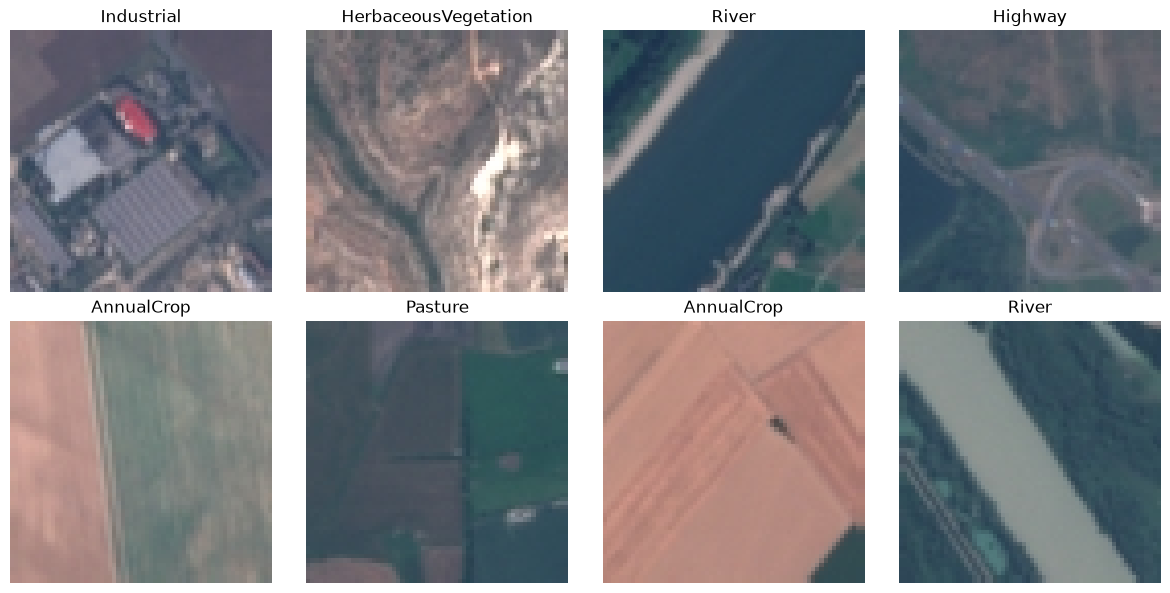

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    img = imagenes[i].permute(1, 2, 0)

    # Desnormalizamos para visualizar
    img = img * 0.5 + 0.5

    ax.imshow(img)
    ax.set_title(clases[etiquetas[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

## **Modelo**

El modelo posee 4 bloques `Conv→BN→ReLU→Conv→BN→ReLU→MaxPool`, con los canales duplicándose y la resolución bajando a la mitad en cada bloque $64→32→16→8→4$.

In [15]:
import torch.nn.functional as F

class BloqueConv(nn.Module):
    """Dos convoluciones 3x3 que preservan el tamaño + pooling que lo reduce a la mitad."""
    def __init__(self, c_in, c_out):
        super().__init__()
        # bias=False porque BatchNorm ya aporta un término de desplazamiento
        self.conv1 = nn.Conv2d(c_in,  c_out, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(c_out)
        self.pool  = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        return self.pool(x)


class CNNPropia(nn.Module):
    def __init__(self, num_clases=10, canales=(32, 64, 128, 256),
                 dim_features=256, p_dropout=0.3):
        super().__init__()
        c1, c2, c3, c4 = canales

        self.bloque1 = BloqueConv(3,  c1)   # 3x64x64   -> c1 x 32 x 32
        self.bloque2 = BloqueConv(c1, c2)   # c1x32x32  -> c2 x 16 x 16
        self.bloque3 = BloqueConv(c2, c3)   # c2x16x16  -> c3 x  8 x  8
        self.bloque4 = BloqueConv(c3, c4)   # c3x8x8    -> c4 x  4 x  4

        self.flatten = nn.Flatten()
        self.fc1     = nn.Linear(c4 * 4 * 4, dim_features)
        self.dropout = nn.Dropout(p_dropout)
        self.fc2     = nn.Linear(dim_features, num_clases)

    def features(self, x):
        """Representación de la imagen JUSTO ANTES de la capa de clasificación.
        La vamos a reutilizar en el ejercicio 2 para t-SNE / PCA."""
        x = self.bloque1(x)
        x = self.bloque2(x)
        x = self.bloque3(x)
        x = self.bloque4(x)
        x = self.flatten(x)
        return F.relu(self.fc1(x))

    def forward(self, x):
        z = self.features(x)
        return self.fc2(self.dropout(z))   # logits crudos: los espera CrossEntropyLoss

In [17]:
def mostrar_shapes(modelo, input_shape=(3, 64, 64)):
    modelo = modelo.to(device).eval()
    hooks = []

    def hook(modulo, entrada, salida):
        print(f"{modulo.__class__.__name__:<12} -> {tuple(salida.shape)}")

    for m in modelo.modules():
        if isinstance(m, (nn.Conv2d, nn.MaxPool2d, nn.Flatten, nn.Linear)):
            hooks.append(m.register_forward_hook(hook))

    with torch.no_grad():
        y = modelo(torch.zeros(1, *input_shape, device=device))

    for h in hooks:
        h.remove()

    print(f"\nSalida final -> {tuple(y.shape)}")
    print(f"Parámetros entrenables: {sum(p.numel() for p in modelo.parameters() if p.requires_grad):,}")


torch.manual_seed(100)          # re-fijamos la semilla justo antes de instanciar
modelo = CNNPropia().to(device)
mostrar_shapes(CNNPropia(num_clases=num_clases))

Conv2d       -> (1, 32, 64, 64)
Conv2d       -> (1, 32, 64, 64)
MaxPool2d    -> (1, 32, 32, 32)
Conv2d       -> (1, 64, 32, 32)
Conv2d       -> (1, 64, 32, 32)
MaxPool2d    -> (1, 64, 16, 16)
Conv2d       -> (1, 128, 16, 16)
Conv2d       -> (1, 128, 16, 16)
MaxPool2d    -> (1, 128, 8, 8)
Conv2d       -> (1, 256, 8, 8)
Conv2d       -> (1, 256, 8, 8)
MaxPool2d    -> (1, 256, 4, 4)
Flatten      -> (1, 4096)
Linear       -> (1, 256)
Linear       -> (1, 10)

Salida final -> (1, 10)
Parámetros entrenables: 2,224,618


## **Entrenamiento**